# CV Day 1 · ⑤ Filter와 Edge Detection 비교

**Module 2. 이미지 처리와 특징 추출 · 실습 B+C · 50분 · CPU · 전원 필수 실습**

④교시의 Gaussian Blur·Sobel Gradient·Canny Edge Detection을 **한 장의 이미지로 반복 비교**합니다. ③교시의 `assets/color_sample.png`를 그대로 사용합니다.

| 구간 | 시간 | 학습 내용 | 바꿀 조건 · 확인할 출력 |
|---|---:|---|---|
| 0. 준비 | 5분 | 원본 이미지·배열 확인 | RGB·Grayscale·`shape`·`dtype` |
| A. Gaussian | 12분 | Kernel 크기별 평활화 | ★ 15 → 21 · 이미지·픽셀 차이 |
| B. Sobel | 13분 | X/Y 방향별 Gradient | ★ `(1,0)` → `(0,1)` · 경계 방향·값 범위 |
| C. Canny | 15분 | Double Threshold | ★ Low 50 → 100 · Edge Map·경계 픽셀 수 |
| E. 정리 | 5분 | 전체 방법 비교 | 원본·Blur·Sobel·Canny 시각화 |

**실습 방법:** 모든 코드 셀을 위에서 아래로 `Shift + Enter`로 실행합니다. **★ 변경할 값**을 한 번에 하나씩 수정하고 다시 실행하여 화면 아래의 이미지·수치를 비교합니다. 실습에 필요한 이미지는 패키지에 포함되어 있으며 인터넷이나 GPU가 필요하지 않습니다.

> **핵심 질문:** 어떤 필터·Threshold를 적용하느냐에 따라 어떤 특징이 추출되며, 어떤 결과가 필요한 경계를 잘 보존했다고 판단할 수 있을까요?

## 0. 실습 준비 및 원본 이미지 확인 (5분)

①·③교시 복습: OpenCV의 `imread()`는 컬러 이미지를 BGR 순서로 읽고, Matplotlib에 표시하려면 RGB로 바꾸어야 합니다. Gradient를 계산할 때는 밝기값의 변화에 집중하기 위해 Grayscale을 사용합니다.

`assets/color_sample.png`는 ③교시에서 사용한 이미지와 동일합니다. Notebook과 `assets` 폴더의 상대 위치를 유지합니다.

OpenCV version: 5.0.0
RGB Shape (H,W,C): (512, 512, 3)
Gray Shape (H,W): (512, 512)
Gray dtype: uint8
Gray min~max: 0 ~ 255


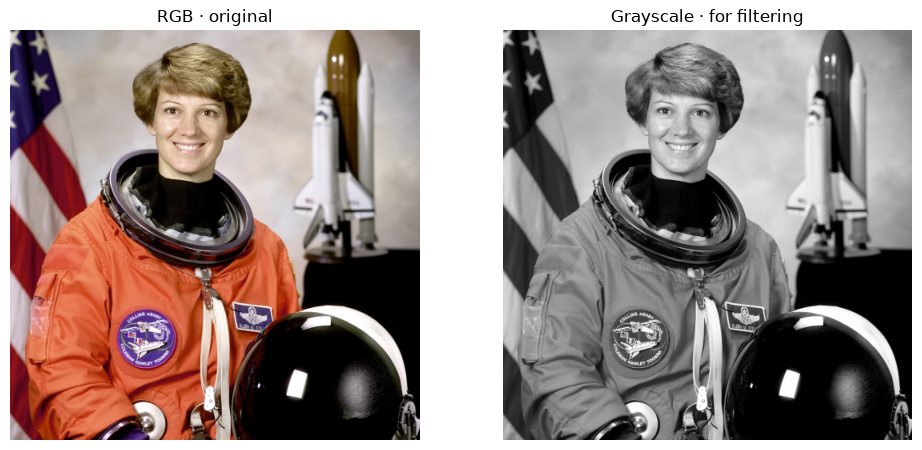

In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

# JupyterLab을 현재 폴더 또는 상위 폴더에서 실행한 경우를 모두 지원합니다.
ASSET_DIR = Path("assets")
if not (ASSET_DIR / "color_sample.png").is_file():
    ASSET_DIR = Path("module2_cv_nlp") / "assets"

COLOR_PATH = ASSET_DIR / "color_sample.png"
if not COLOR_PATH.is_file():
    raise FileNotFoundError(f"실습 이미지가 없습니다: {COLOR_PATH.resolve()}")

bgr = cv2.imread(str(COLOR_PATH), cv2.IMREAD_COLOR)
if bgr is None:
    raise RuntimeError(f"OpenCV가 이미지 파일을 열지 못했습니다: {COLOR_PATH}")

rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

print("OpenCV version:", cv2.__version__)
print("RGB Shape (H,W,C):", rgb.shape)
print("Gray Shape (H,W):", gray.shape)
print("Gray dtype:", gray.dtype)
print("Gray min~max:", int(gray.min()), "~", int(gray.max()))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
axes[0].imshow(rgb)
axes[0].set_title("RGB · original")
axes[1].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Grayscale · for filtering")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**중간 결과 확인 ①**: `RGB (512, 512, 3)`, `Gray (512, 512)`, `dtype=uint8`이 표시되는지 확인합니다. 앞으로는 **동일한 Grayscale 원본**으로 결과를 비교합니다.

## A-1. Gaussian Kernel 크기별 Blur 비교 (6분)

**이론 연결:** Gaussian Blur는 주변 픽셀을 Gaussian 가중평균하여 밝기 변화를 부드럽게 만듭니다. 이번 비교에서는 `sigmaX=0`으로 두어 OpenCV가 Kernel 크기 등을 바탕으로 Sigma를 정하게 합니다. **Kernel Size와 자동 결정된 Sigma가 함께 달라지는 실험**입니다.

원본·3×3·7×7·15×15 이미지를 한 화면에 표시하고, 원본 대비 **평균 절댓값 차이(MAE)**도 계산합니다. MAE는 영상이 *얼마나 달라졌는지* 나타낼 뿐 노이즈 제거 성능이나 품질 점수가 아닙니다.

[원본 대비 평균 절댓값 차이 · 픽셀값 0~255 기준]
Gaussian  3x 3: MAE = 2.88
Gaussian  7x 7: MAE = 5.44
Gaussian 15x15: MAE = 9.16


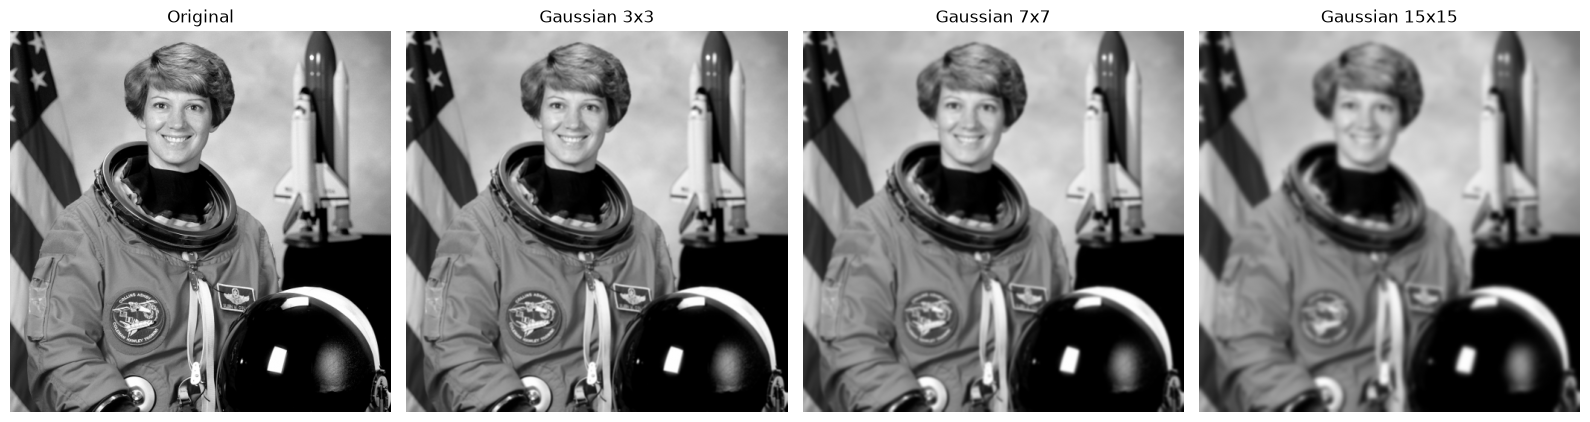

In [2]:
# Kernel 크기는 양의 홀수여야 합니다.
kernel_sizes = [3, 7, 15]
blur_results = {}

for k in kernel_sizes:
    blur_results[k] = cv2.GaussianBlur(gray, (k, k), sigmaX=0)

print("[원본 대비 평균 절댓값 차이 · 픽셀값 0~255 기준]")
for k, blurred in blur_results.items():
    diff = np.abs(gray.astype(np.float32) - blurred.astype(np.float32))
    print(f"Gaussian {k:2d}x{k:2d}: MAE = {diff.mean():.2f}")

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
items = [("Original", gray)] + [(f"Gaussian {k}x{k}", blur_results[k]) for k in kernel_sizes]
for ax, (title, image) in zip(axes, items):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

**중간 결과 확인 ②**: Kernel이 커지면 머리카락·의상·헬멧 등에 있는 가는 무늬와 경계가 어떻게 달라지나요? MAE가 커졌다고 해서 영상 품질이 개선되었다고 해석하지 마세요.

## A-2. ★ Kernel 15 → 21 변경하여 직접 비교 (6분)

**★ 변경할 값:** 첫 실행 후 아래 `experiment_kernel = 15`를 **21**로 바꾸어 다시 실행합니다. 원래 15×15 결과는 *고정 비교 기준*으로 유지합니다.

전체 이미지에서 차이가 작게 보일 수 있으므로, 머리카락이 포함된 작은 영역도 확대하여 비교합니다. **비교 시에는 같은 위치를 잘라야 합니다.**

기준 Kernel: 15x15
변경 Kernel: 15x15
기준과 변경 결과의 평균 절댓값 차이: 0.00


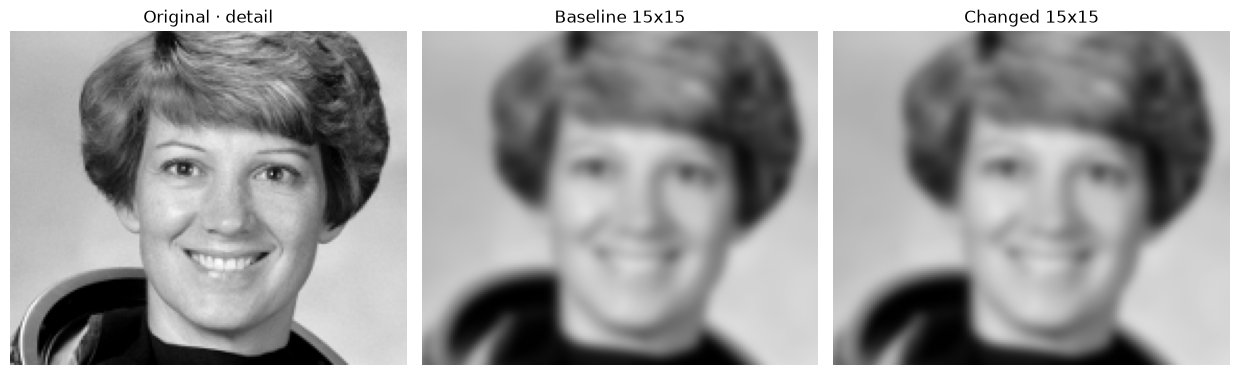

In [3]:
# 고정 기준: 15x15
baseline_kernel = 15
baseline = cv2.GaussianBlur(gray, (baseline_kernel, baseline_kernel), sigmaX=0)

# ★ 변경할 값: 15 → 21
experiment_kernel = 15
assert experiment_kernel >= 3 and experiment_kernel % 2 == 1, "Kernel 크기는 3 이상의 홀수여야 합니다."
experiment = cv2.GaussianBlur(gray, (experiment_kernel, experiment_kernel), sigmaX=0)

# 동일한 위치의 머리카락/윤곽 영역을 확대합니다.
roi = np.s_[35:195, 120:310]
comparison = np.abs(baseline.astype(np.float32) - experiment.astype(np.float32))
print(f"기준 Kernel: {baseline_kernel}x{baseline_kernel}")
print(f"변경 Kernel: {experiment_kernel}x{experiment_kernel}")
print(f"기준과 변경 결과의 평균 절댓값 차이: {comparison.mean():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.3))
for ax, (title, im) in zip(axes, [
    ("Original · detail", gray[roi]),
    (f"Baseline {baseline_kernel}x{baseline_kernel}", baseline[roi]),
    (f"Changed {experiment_kernel}x{experiment_kernel}", experiment[roi]),
]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

**관찰 질문 A:** 15에서 21로 변경했을 때 가는 무늬와 경계 중 어떤 부분의 차이가 큰가요? 전체 이미지와 확대 영역을 함께 확인합니다. **Blur를 강하게 할수록 무조건 더 좋다는 결론은 내리지 않습니다.**

## B-1. Sobel X·Y·Gradient Magnitude 비교 (7분)

**이론 연결:** Sobel X는 좌우(x좌표) 방향 밝기 변화를 계산하므로 보통 **세로 경계**에, Sobel Y는 상하(y좌표) 방향 밝기 변화를 계산하므로 보통 **가로 경계**에 강하게 반응합니다.

- `CV_64F`: 음수와 255보다 큰 Gradient 값 보존
- `convertScaleAbs()`: 절댓값을 취하고 0~255로 제한하여 **보기 위한 이미지** 생성 (원본 Gradient 부호와 일부 크기 정보 손실 가능)
- Magnitude: `sqrt(Gx² + Gy²)`로 두 방향의 변화량 결합

계산용 배열과 시각화용 이미지를 구별합니다.

Sobel X: dtype=float64, min=-952.0, max=968.0
Sobel Y: dtype=float64, min=-855.0, max=1000.0
Sobel X의 음수 픽셀 수: 122056
Sobel X의 255 초과 픽셀 수: 4262


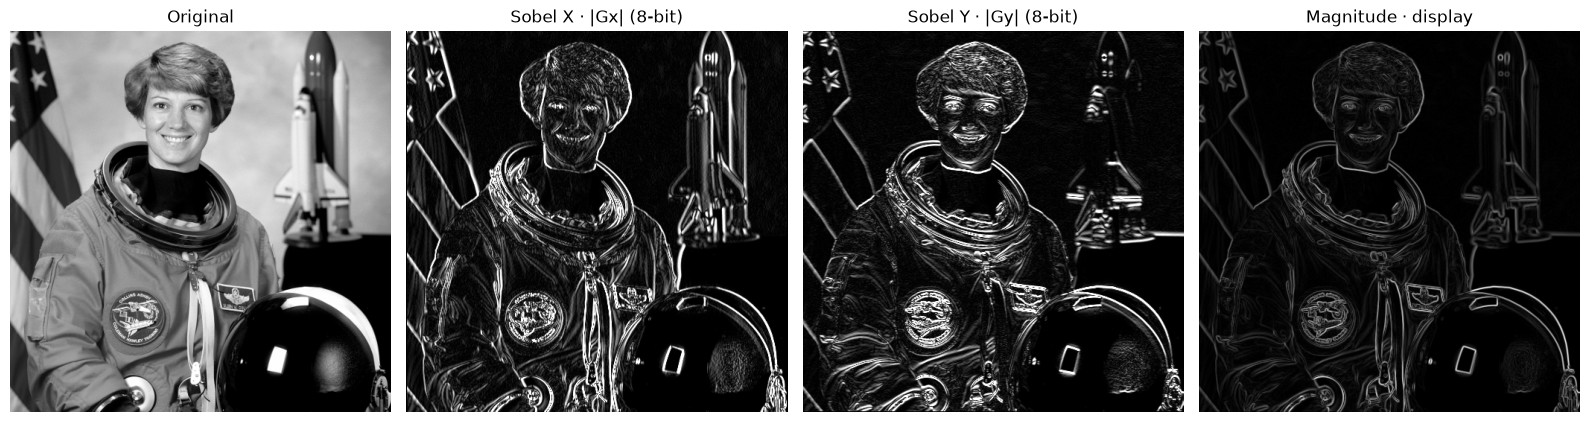

In [4]:
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

sobel_x_view = cv2.convertScaleAbs(sobel_x)
sobel_y_view = cv2.convertScaleAbs(sobel_y)

gradient_magnitude = cv2.magnitude(
    sobel_x.astype(np.float32), sobel_y.astype(np.float32)
)
# Magnitude 시각화를 위한 0~255 재조정입니다. 정량 비교는 원본 실수 배열을 사용합니다.
mag_view = cv2.normalize(
    gradient_magnitude, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

print(f"Sobel X: dtype={sobel_x.dtype}, min={sobel_x.min():.1f}, max={sobel_x.max():.1f}")
print(f"Sobel Y: dtype={sobel_y.dtype}, min={sobel_y.min():.1f}, max={sobel_y.max():.1f}")
print("Sobel X의 음수 픽셀 수:", int(np.count_nonzero(sobel_x < 0)))
print("Sobel X의 255 초과 픽셀 수:", int(np.count_nonzero(sobel_x > 255)))

fig, axes = plt.subplots(1, 4, figsize=(16, 4.3))
items = [
    ("Original", gray),
    ("Sobel X · |Gx| (8-bit)", sobel_x_view),
    ("Sobel Y · |Gy| (8-bit)", sobel_y_view),
    ("Magnitude · display", mag_view),
]
for ax, (title, arr) in zip(axes, items):
    ax.imshow(arr, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

**중간 결과 확인 ③**: 같은 사진에서도 X/Y 방향에 따라 강조되는 경계가 다릅니다. `dtype=float64`, 음수·255 초과 값이 나타나는지 확인합니다. `convertScaleAbs()`의 출력은 Gradient 원본값이 아니라 **시각화용**입니다.

## B-2. ★ 미분 방향 `(1,0)` → `(0,1)` (6분)

실제 사진에서는 여러 방향의 경계가 섞여 있어 구분이 어려울 수 있습니다. 그래서 **좌우로 밝기가 바뀌는 이미지**와 **상하로 밝기가 바뀌는 이미지**를 직접 만듭니다. 입력 조건을 통제하여 Sobel이 어떤 경계에 반응하는지 확인합니다.

**★ 변경할 값:** `dx, dy = 1, 0`으로 실행한 뒤 `dx, dy = 0, 1`로 바꾸어 다시 실행합니다.

선택한 미분 방향 (dx, dy) = (1, 0)
세로 경계 입력 · Gradient 절댓값 합: 195840
가로 경계 입력 · Gradient 절댓값 합: 0


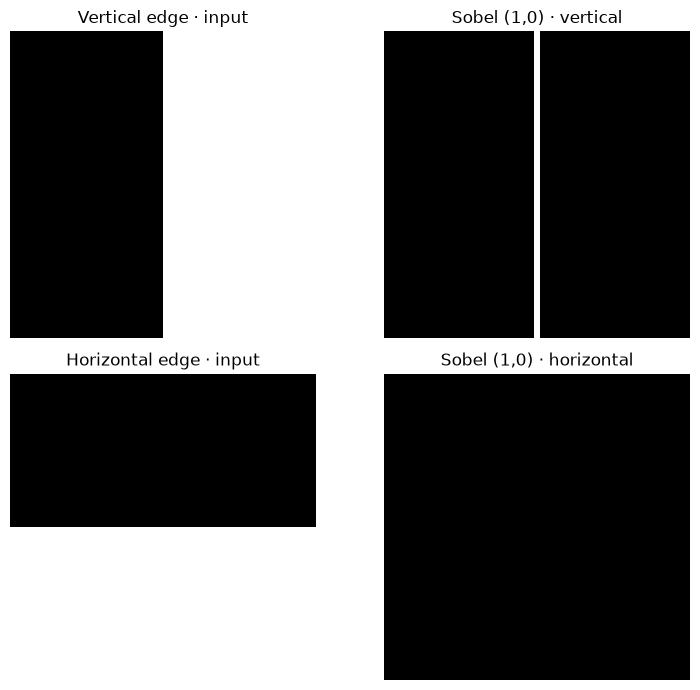

In [5]:
# 비교를 위한 인공 입력 두 장: 좌우 밝기 변화 vs 상하 밝기 변화
vertical_step = np.zeros((96, 96), dtype=np.uint8)
vertical_step[:, 48:] = 255      # 세로 경계: 좌우 방향으로 밝기 변화

horizontal_step = np.zeros((96, 96), dtype=np.uint8)
horizontal_step[48:, :] = 255    # 가로 경계: 상하 방향으로 밝기 변화

# ★ 변경할 값: (1, 0) → (0, 1)
dx, dy = 1, 0
assert (dx, dy) in [(1, 0), (0, 1)]

v_grad = cv2.Sobel(vertical_step, cv2.CV_64F, dx, dy, ksize=3)
h_grad = cv2.Sobel(horizontal_step, cv2.CV_64F, dx, dy, ksize=3)

print(f"선택한 미분 방향 (dx, dy) = ({dx}, {dy})")
print("세로 경계 입력 · Gradient 절댓값 합:", int(np.abs(v_grad).sum()))
print("가로 경계 입력 · Gradient 절댓값 합:", int(np.abs(h_grad).sum()))

fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for ax, image, title in zip(
    axes.ravel(),
    [vertical_step, cv2.convertScaleAbs(v_grad),
     horizontal_step, cv2.convertScaleAbs(h_grad)],
    ["Vertical edge · input", f"Sobel ({dx},{dy}) · vertical",
     "Horizontal edge · input", f"Sobel ({dx},{dy}) · horizontal"],
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

**관찰 질문 B:** x방향 미분이 **세로 경계**에 반응하는 이유를 설명해 보세요. 방향을 바꿨을 때 두 입력 중 어느 쪽의 Gradient가 커졌나요? `Sobel X = 세로 경계에 강하게 반응`과 `Sobel X = x방향 밝기 변화 계산`은 같은 현상을 서로 다른 관점에서 말한 것입니다.

## C-1. Gaussian 전처리 후 Canny 기본 실행 (4분)

Canny는 Gradient 기반의 강한/약한 경계 후보를 구분하고 연결 관계를 이용해 Edge Map을 만듭니다. 이번에는 **Gaussian Blur 조건을 먼저 고정**해 두고 Threshold만 변경하겠습니다.

**주의:** ②교시의 Thresholding은 **픽셀 밝기값**을, Canny의 Threshold는 **Gradient 기반 경계 강도**를 판단합니다. `cv2.Canny()` 내부에서 이 Notebook의 별도 Gaussian Blur 단계가 자동 반복된다고 가정하지 마세요.

Canny 출력 Shape: (512, 512)
Canny 출력 dtype: uint8
Canny 픽셀값 종류: [0, 255]
기본 Edge 픽셀 수: 18039


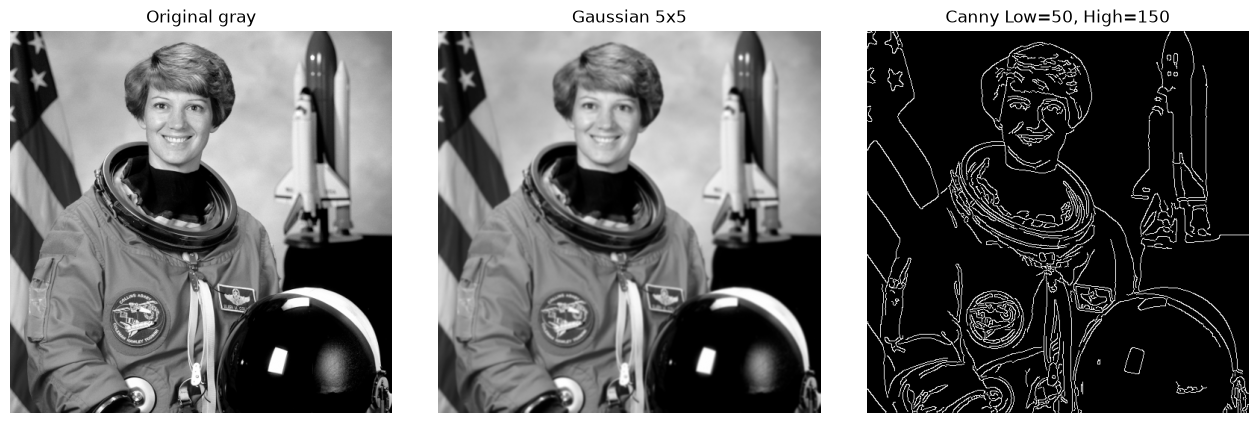

In [6]:
# Canny 입력으로 사용할 이미지: 모든 C 실험에서 동일하게 유지합니다.
canny_input = cv2.GaussianBlur(gray, (5, 5), sigmaX=0)

base_low, base_high = 50, 150
base_edges = cv2.Canny(canny_input, base_low, base_high)

print("Canny 출력 Shape:", base_edges.shape)
print("Canny 출력 dtype:", base_edges.dtype)
print("Canny 픽셀값 종류:", np.unique(base_edges).tolist())
print("기본 Edge 픽셀 수:", int(np.count_nonzero(base_edges)))

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (title, arr) in zip(axes, [
    ("Original gray", gray),
    ("Gaussian 5x5", canny_input),
    (f"Canny Low={base_low}, High={base_high}", base_edges),
]):
    ax.imshow(arr, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

**중간 결과 확인 ④**: Edge Map의 흰색 픽셀(255)은 **객체 내부가 아니라 선택된 경계 위치**입니다. `np.unique()` 결과가 `[0, 255]`인지 확인합니다.

## C-2. Low·High Threshold 세 조합 비교 (6분)

같은 `canny_input`에 다음 세 조건을 적용합니다.

- A: Low=30, High=90
- B: Low=50, High=150
- C: Low=120, High=240

**조합이 높아지면 일반적으로 약한 경계가 줄어들 수 있습니다.** 이번 비교에서는 Low와 High가 **함께 변경**되므로 한쪽의 독립적인 영향으로 해석하지 않습니다. Edge 픽셀 수는 결과를 해석하는 보조 지표이며 정확도 점수가 아닙니다.

[동일 입력의 Canny Edge 픽셀 수]
Low= 30, High= 90: 23,824개 (9.09%)
Low= 50, High=150: 18,039개 (6.88%)
Low=120, High=240: 11,888개 (4.53%)


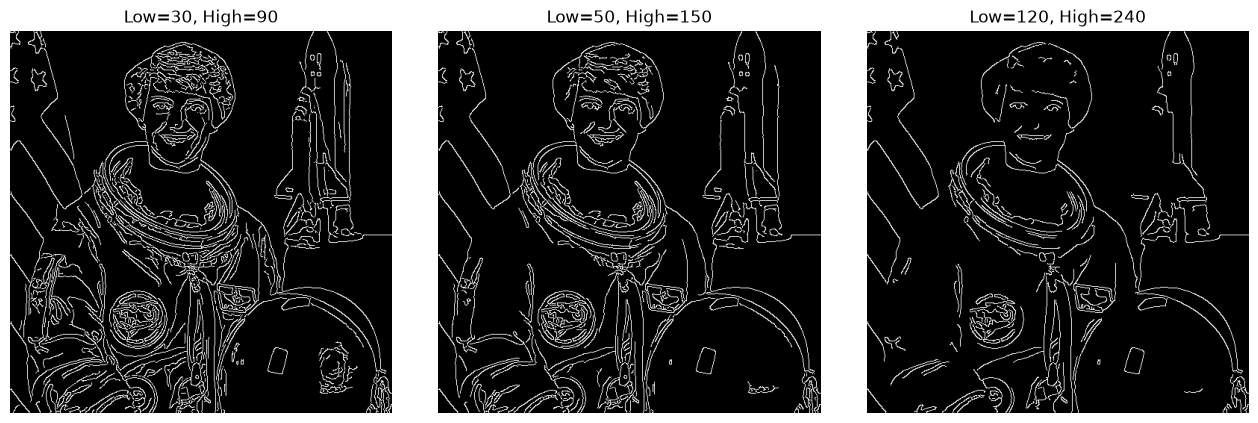

In [7]:
threshold_pairs = [(30, 90), (50, 150), (120, 240)]
edge_results = {}

for low, high in threshold_pairs:
    edge_results[(low, high)] = cv2.Canny(canny_input, low, high)

print("[동일 입력의 Canny Edge 픽셀 수]")
for (low, high), edge_map in edge_results.items():
    n_edge = int(np.count_nonzero(edge_map))
    percent = n_edge / edge_map.size * 100
    print(f"Low={low:3d}, High={high:3d}: {n_edge:,}개 ({percent:.2f}%)")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, ((low, high), edge_map) in zip(axes, edge_results.items()):
    ax.imshow(edge_map, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Low={low}, High={high}")
    ax.axis("off")
plt.tight_layout()
plt.show()

**중간 결과 확인 ⑤**: 이 이미지에서는 조건 A → C로 갈수록 Edge 픽셀 수가 줄어드는지 확인합니다. **더 많이 검출됐다는 이유만으로 더 좋은 결과라고 판단하지 않습니다.** 필요한 물체 윤곽이 남아 있는지 이미지와 함께 살펴봅니다.

## C-3. ★ High=150 고정, Low=50 → 100 (5분)

앞 실습과 달리 **High Threshold는 그대로** 두고 Low만 바꿉니다. 강한 경계 판단 기준은 유지한 채 약한 경계 후보의 조건을 살펴보는 실험입니다.

**★ 변경할 값:** `low_test = 50`으로 실행하고, **100**으로 바꿔 다시 실행합니다. 오른쪽 차이 지도에서 흰 부분은 기준 결과와 달라진 위치입니다.

기준 Low=50, High=150: 18,039개
변경 Low=50, High=150: 18,039개
서로 다른 결과 픽셀 수: 0개


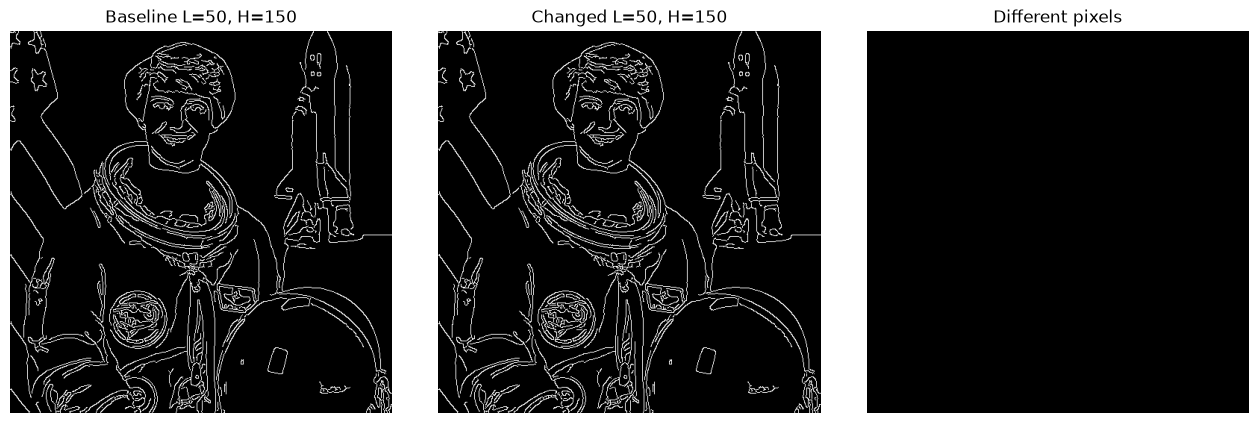

In [8]:
fixed_high = 150
baseline_low = 50
baseline_edges = cv2.Canny(canny_input, baseline_low, fixed_high)

# ★ 변경할 값: 50 → 100 (추가로 30도 확인할 수 있습니다)
low_test = 50
assert 0 <= low_test < fixed_high, "0 <= Low < High 조건을 확인하세요."
changed_edges = cv2.Canny(canny_input, low_test, fixed_high)

changed_pixels = int(np.count_nonzero(baseline_edges != changed_edges))
print(f"기준 Low={baseline_low}, High={fixed_high}: {np.count_nonzero(baseline_edges):,}개")
print(f"변경 Low={low_test}, High={fixed_high}: {np.count_nonzero(changed_edges):,}개")
print("서로 다른 결과 픽셀 수:", f"{changed_pixels:,}개")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (title, arr) in zip(axes, [
    (f"Baseline L={baseline_low}, H={fixed_high}", baseline_edges),
    (f"Changed L={low_test}, H={fixed_high}", changed_edges),
    ("Different pixels", cv2.absdiff(baseline_edges, changed_edges)),
]):
    ax.imshow(arr, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

**관찰 질문 C:** Low만 50 → 100으로 올렸을 때 **유지된 경계**와 **사라진 경계**는 어디인가요? Hysteresis는 강한 Edge와 연결되는 약한 Edge를 유지한다는 ④교시 원리와 연결해 해석합니다.

## E. 원본·Blur·Sobel·Canny 종합 비교 (5분)

④교시의 이론과 ⑤교시의 실습 결과를 한 화면에 정리합니다. **원본 이미지 → Gaussian → Sobel → Canny가 언제나 하나의 고정된 직렬 처리 순서라는 뜻은 아닙니다.** 여기서는 원본의 Sobel과 Gaussian을 적용한 Canny를 비교합니다.

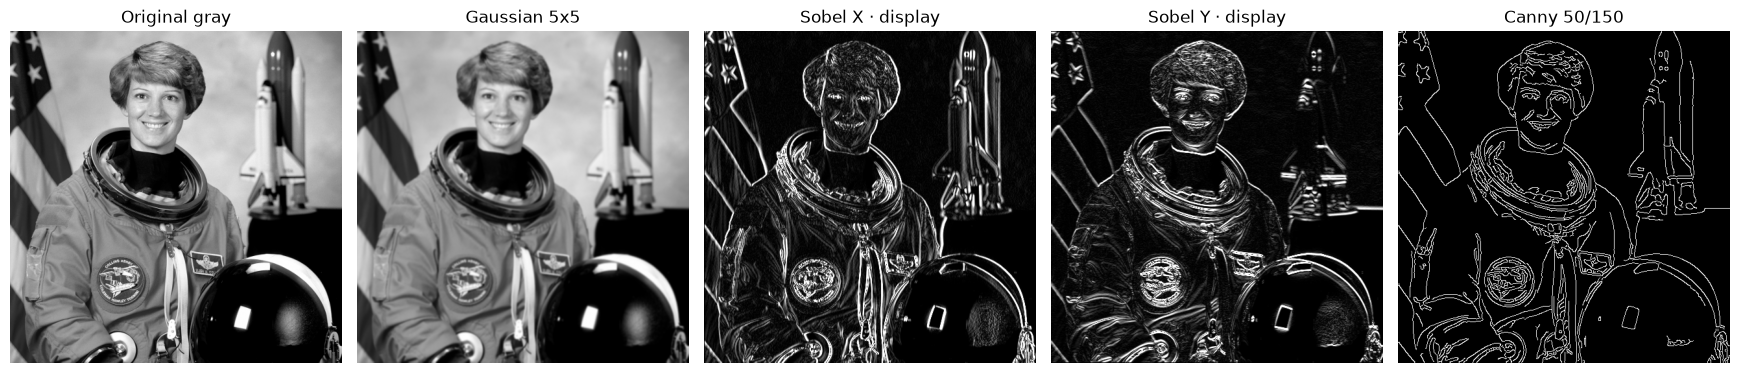

요약: Blur=평활화 | Sobel=방향별 밝기 변화 | Canny=최종 경계 후보 선택


In [9]:
fig, axes = plt.subplots(1, 5, figsize=(17.5, 4.2))
final_images = [
    ("Original gray", gray),
    ("Gaussian 5x5", canny_input),
    ("Sobel X · display", sobel_x_view),
    ("Sobel Y · display", sobel_y_view),
    ("Canny 50/150", base_edges),
]
for ax, (title, image) in zip(axes, final_images):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

print("요약: Blur=평활화 | Sobel=방향별 밝기 변화 | Canny=최종 경계 후보 선택")

### 오늘의 관찰 결과를 문장으로 정리합니다

| 비교 항목 | 직접 확인한 결과 |
|---|---|
| Gaussian Kernel 15 → 21 | 내가 관찰한 세부 정보 변화: __________ |
| Sobel X/Y | Sobel X가 강조한 방향: __________ / Sobel Y가 강조한 방향: __________ |
| Canny (30/90, 50/150, 120/240) | Edge 픽셀 수와 주요 윤곽의 변화: __________ |
| High=150 고정, Low 50 → 100 | 유지되거나 사라진 경계: __________ |

**핵심 구분**

| 기법 | 무엇을 계산하거나 선택하나요? | 결과의 대표적 형태 |
|---|---|---|
| Gaussian Blur | 주변 픽셀의 가중평균 | 부드러워진 이미지 |
| Sobel | 방향별 밝기 변화 | 양수·음수 Gradient |
| Canny | Gradient 기반 경계 후보 선택 | 0/255 Edge Map |

**다음 학습 연결:** 이번 시간에는 사람이 설계한 필터와 알고리즘으로 이미지의 특징을 추출했습니다. ⑥교시에서는 CNN이 필터 가중치를 **데이터로부터 학습하는 방식**을 배우고, ⑦교시에서 실제 학습된 Feature Map을 관찰하겠습니다.